## 10. Sistemas de EDOs: da equação de ordem superior ao sistema

Muitos fenômenos envolvem várias grandezas que variam ao mesmo tempo e influenciam umas às outras: as posições de massas ligadas por molas, as correntes nas malhas de um circuito, as quantidades de sal em tanques interligados, as populações de presas e predadores. Os modelos matemáticos desses fenômenos são **sistemas de EDOs**.

Neste notebook veremos como escrever esses sistemas na forma matricial, como transformar uma EDO (ou várias) de ordem superior num sistema de 1ª ordem — generalizando o que fizemos no Notebook 8 — e como visualizar as soluções no **plano de fase**.

<img src="https://raw.githubusercontent.com/tiagoburiol/MatComp_III/refs/heads/main/Notebook%2010%20-%20Sistemas%20de%20EDOs%2C%20da%20ordem%20superior%20ao%20sistema/imagens/aplicacoes_sistemas.png" width="1000">

<center> Figura 1: Exemplos de aplicações de sistemas de EDOs </center>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp
sp.init_printing()

### 10.1 Sistemas lineares de 1ª ordem

Sistemas de $n$ equações lineares de primeira ordem têm a forma
$$
\begin{gathered}
x_1^{\prime}=p_{11}(t) x_1+\cdots+p_{1 n}(t) x_n+g_1(t), \\
\vdots \\
x_n^{\prime}=p_{n 1}(t) x_1+\cdots+p_{n n}(t) x_n+g_n(t)
\end{gathered}
$$

e podem ser representados em notação matricial na forma
$$
\mathbf{x}^{\prime}=\mathbf{P}(t) \mathbf{x}+\mathbf{g}(t)
$$

em que $x_1 = x_1(t)$, ..., $x_n = x_n(t)$ são componentes de um vetor $\mathbf{x} = \mathbf{x}(t)$. Analogamente, $g_1(t)$, ..., $g_n(t)$ são componentes de um vetor $\mathbf{g}(t)$ e $p_{11}(t)$, ..., $p_{nn}(t)$ são elementos de uma matriz $n \times n$ denotada por $\mathbf{P}(t)$.

Um vetor $\mathbf{x} = \mathbf{x}(t)$ é uma solução do sistema se satisfizer a equação matricial (isto é, todas as equações do sistema).

Se $\mathbf{g}(t) = \mathbf{0}$, o sistema é dito **homogêneo**. Para sistemas homogêneos vale o **princípio da superposição**: se $\mathbf{x}^{(1)}$ e $\mathbf{x}^{(2)}$ são soluções de $\mathbf{x}'=\mathbf{P}(t)\mathbf{x}$, então a combinação linear $c_1 \mathbf{x}^{(1)}+c_2 \mathbf{x}^{(2)}$ também é solução, quaisquer que sejam as constantes $c_1$ e $c_2$ (o mesmo princípio que vimos para EDOs lineares homogêneas de 2ª ordem no Notebook 7). Para sistemas não homogêneos isso **não** vale: a soma de duas soluções de $\mathbf{x}'=\mathbf{P}\mathbf{x}+\mathbf{g}$ satisfaz $\mathbf{x}'=\mathbf{P}\mathbf{x}+2\mathbf{g}$.

**Exemplo 10.1:** Verificar que

$$\mathbf{x}^{(1)}(t)=\binom{e^{3 t}}{2 e^{3 t}}=\binom{1}{2} e^{3 t}, \quad \mathbf{x}^{(2)}(t)=\binom{e^{-t}}{-2 e^{-t}}=\binom{1}{-2} e^{-t}$$

satisfazem a equação

$$\mathbf{x}^{\prime}=\left(\begin{array}{ll}1 & 1 \\ 4 & 1\end{array}\right) \mathbf{x} \text{.}$$

Em caso afirmativo para ambas, verifique que $c_1 \mathbf{x}^{(1)}+c_2 \mathbf{x}^{(2)}$ também satisfaz.

*Solução:* Vamos usar o `SymPy`. Para verificar que $\mathbf{x}$ é solução, calculamos o **resíduo** $\mathbf{x}'-\mathbf{A}\mathbf{x}$ e simplificamos: o resultado deve ser o vetor nulo.

In [2]:
t, c1, c2 = sp.symbols('t c_1 c_2')
x1 = sp.Matrix([1,2])*sp.exp(3*t)
x2 = sp.Matrix([1,-2])*sp.exp(-t)
A = sp.Matrix([[1,1],[4,1]])

def residuo(A, x):
    """Resíduo x' - A x, simplificado (é o vetor nulo se x for solução de x' = A x)."""
    return sp.simplify(x.diff(t) - A*x)

display(residuo(A, x1), residuo(A, x2))

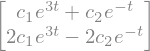

In [3]:
# combinação linear das duas soluções
sol = c1*x1 + c2*x2
display(sol, residuo(A, sol))

Os três resíduos são nulos, logo $\mathbf{x}^{(1)}$, $\mathbf{x}^{(2)}$ e $c_1\mathbf{x}^{(1)}+c_2\mathbf{x}^{(2)}$ são soluções.

> **Por que não usar `==`?** Em SymPy, `x1.diff(t) == A*x1` compara a *forma* das expressões, não o seu valor matemático: duas expressões iguais escritas de formas diferentes (por exemplo, $2e^{3t}+e^{3t}$ e $3e^{3t}$ antes da simplificação) podem dar `False`. Calcular a diferença e simplificar é a forma segura de testar igualdade.

#### Atividade 10.1

Verifique que $\mathbf{x}^{(1)}=\binom{2}{1}e^{2t}$ e $\mathbf{x}^{(2)}=\binom{1}{2}e^{-t}$ são soluções de $\mathbf{x}'=\left(\begin{array}{rr}3 & -2 \\ 2 & -2\end{array}\right)\mathbf{x}$ e que $c_1\mathbf{x}^{(1)}+c_2\mathbf{x}^{(2)}$ também é. Em seguida, verifique que $\mathbf{x}^{(1)}$ **não** é solução do sistema não homogêneo $\mathbf{x}'=\left(\begin{array}{rr}3 & -2 \\ 2 & -2\end{array}\right)\mathbf{x}+\binom{1}{0}$.

### 10.2 Escrevendo uma ou mais EDOs de ordem superior como um sistema de 1ª ordem

No Notebook 8 (Seção 8.1) reescrevemos uma EDO de 2ª ordem como um sistema de duas EDOs de 1ª ordem. A mesma ideia vale para qualquer ordem: uma equação diferencial de ordem $n$,
$$
x^{(n)}=f\left(t, x, x^{\prime}, x^{\prime \prime}, \ldots, x^{(n-1)}\right),
$$
pode ser escrita de forma equivalente como um sistema de $n$ equações diferenciais de primeira ordem.

Para isso, basta definir $x_1, x_2, \ldots, x_n$ da seguinte forma:
$$
x_1=x, \quad x_2=x^{\prime}, \quad x_3=x^{\prime \prime}, \quad \ldots, \quad x_n=x^{(n-1)} .
$$

Assim, obtemos o sistema
$$
\begin{cases}x_1^{\prime} & =x_2, \\ x_2^{\prime} & =x_3, \\ & \vdots \\ x_{n-1}^{\prime} & =x_n, \\ x_n^{\prime} & =f\left(t, x_1, x_2, \ldots, x_n\right) .\end{cases}
$$

As $n$ condições iniciais $x(t_0), x'(t_0), \ldots, x^{(n-1)}(t_0)$ viram as condições iniciais $x_1(t_0), \ldots, x_n(t_0)$ do sistema.

**Exemplo 10.2:** (Kreyszig, 2008) Modelo de movimentos livres de uma massa presa a uma mola

$$
m y^{\prime \prime}+c y^{\prime}+k y=0 \quad \text { ou } \quad y^{\prime \prime}=-\frac{c}{m} y^{\prime}-\frac{k}{m} y .
$$

Com $y_1=y$ e $y_2=y'$, o sistema (linear e homogêneo) equivalente é

$$
\begin{aligned}
& y_1^{\prime}=y_2 \\
& y_2^{\prime}=-\frac{k}{m} y_1-\frac{c}{m} y_2
\end{aligned}
\qquad\text{ou}\qquad
\mathbf{y}'=\left(\begin{array}{cc}0 & 1 \\ -k/m & -c/m\end{array}\right)\mathbf{y}.
$$

**Exemplo 10.3:** A equação
$$
x^{\prime \prime \prime}+3 x^{\prime \prime}+2 x^{\prime}-5 x=\operatorname{sen}(2 t),
$$

tem como sistema equivalente

$$
\left\{\begin{array}{l}
x_1^{\prime}=x_2, \\
x_2^{\prime}=x_3, \\
x_3^{\prime}=5 x_1-2 x_2-3 x_3+\operatorname{sen}(2 t) .
\end{array}\right.
$$

Escrito assim, o problema pode ser resolvido numericamente por qualquer método para sistemas de 1ª ordem — por exemplo, o `solve_ivp` do SciPy (Notebook 5), que já trabalha com vetores. Vamos resolver o PVI com $x(0)=1$, $x'(0)=0$, $x''(0)=0$ no intervalo $[0,3]$. A função passada ao `solve_ivp` recebe $t$ e o vetor $(x_1,x_2,x_3)$ e devolve o vetor das derivadas.

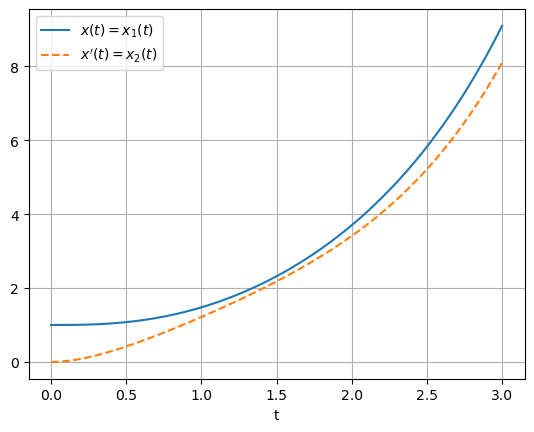

x(3) ≈ 9.095325973857554


In [4]:
def F3(t, x):
    x1, x2, x3 = x
    return [x2, x3, 5*x1 - 2*x2 - 3*x3 + np.sin(2*t)]

ts = np.linspace(0, 3, 200)
s = solve_ivp(F3, (0, 3), [1, 0, 0], t_eval=ts, rtol=1e-8)

plt.plot(s.t, s.y[0], label='$x(t)=x_1(t)$')
plt.plot(s.t, s.y[1], '--', label="$x'(t)=x_2(t)$")
plt.xlabel('t'); plt.legend(); plt.grid()
plt.show()
print('x(3) ≈', s.y[0,-1])

A solução cresce rapidamente porque a equação característica $r^3+3r^2+2r-5=0$ tem uma raiz real positiva ($r\approx0,904$), o que dá um termo $e^{0,904\,t}$ na solução geral.

A mesma técnica vale quando temos **mais de uma** EDO de ordem superior acopladas: basta introduzir uma nova variável para cada derivada de cada incógnita.

**Exemplo 10.4:** *Duas massas acopladas por molas.* Duas massas $m_1=m_2=1$ estão presas em série por duas molas, a primeira (constante $k_1=3$) ligada a uma parede e a segunda ($k_2=2$) ligando as duas massas. Sendo $y_1$ e $y_2$ os deslocamentos das massas em relação ao equilíbrio, a 2ª lei de Newton dá

$$
\begin{aligned}
m_1y_1'' &= -k_1y_1 + k_2(y_2-y_1) \\
m_2y_2'' &= -k_2(y_2-y_1)
\end{aligned}
\qquad\Longrightarrow\qquad
\begin{aligned}
y_1'' &= -5y_1 + 2y_2 \\
y_2'' &= 2y_1 - 2y_2
\end{aligned}
$$

São duas EDOs de 2ª ordem acopladas. Definindo $u_1=y_1$, $u_2=y_1'$, $u_3=y_2$, $u_4=y_2'$, obtemos um sistema de **quatro** EDOs de 1ª ordem:

$$
\mathbf{u}'=\left(\begin{array}{rrrr}
0 & 1 & 0 & 0\\
-5 & 0 & 2 & 0\\
0 & 0 & 0 & 1\\
2 & 0 & -2 & 0
\end{array}\right)\mathbf{u}.
$$

Vamos resolvê-lo com as massas partindo do repouso, com $y_1(0)=1$ e $y_2(0)=2$. Para essa condição inicial particular, a solução exata é $y_1(t)=\cos t$, $y_2(t)=2\cos t$ (verifique substituindo nas equações): as duas massas oscilam em fase, com a mesma frequência — um **modo normal** de vibração do sistema.

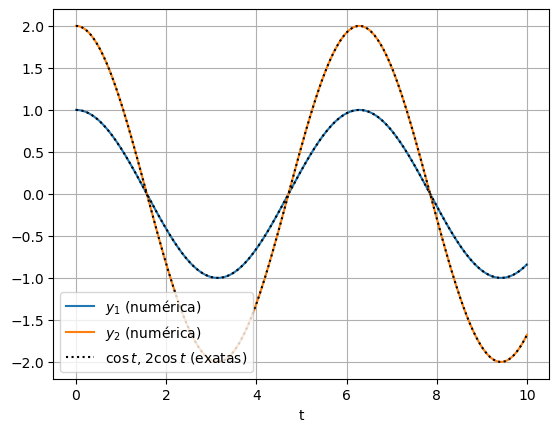

erro máximo em y1: 1.2050432096621932e-08
erro máximo em y2: 2.4100865081422285e-08


In [5]:
def F_massas(t, u):
    u1, u2, u3, u4 = u
    return [u2, -5*u1 + 2*u3, u4, 2*u1 - 2*u3]

ts = np.linspace(0, 10, 300)
s = solve_ivp(F_massas, (0, 10), [1, 0, 2, 0], t_eval=ts, rtol=1e-8, atol=1e-10)

plt.plot(s.t, s.y[0], label='$y_1$ (numérica)')
plt.plot(s.t, s.y[2], label='$y_2$ (numérica)')
plt.plot(ts, np.cos(ts), 'k:', label='$\\cos t$, $2\\cos t$ (exatas)')
plt.plot(ts, 2*np.cos(ts), 'k:')
plt.xlabel('t'); plt.legend(loc='lower left'); plt.grid()
plt.show()
print('erro máximo em y1:', np.max(np.abs(s.y[0] - np.cos(ts))))
print('erro máximo em y2:', np.max(np.abs(s.y[2] - 2*np.cos(ts))))

#### Atividade 10.2

Resolva o sistema do Exemplo 10.4 com as massas partindo do repouso, agora com $y_1(0)=2$ e $y_2(0)=-1$, no intervalo $[0,10]$. Compare com $y_1(t)=2\cos(\sqrt6\,t)$ e $y_2(t)=-\cos(\sqrt6\,t)$ (o outro modo normal, em que as massas oscilam em oposição de fase) e calcule o erro máximo.

### 10.3 Sistemas de coeficientes constantes. Método do plano de fase

Consideremos agora um sistema com coeficientes constantes consistindo em duas EDOs

$$\mathbf{y}^{\prime}=\mathbf{A y}$$

em componentes

$$
y_1^{\prime}=a_{11} y_1+a_{12} y_2
$$

$$
y_2^{\prime}=a_{21} y_1+a_{22} y_2 .
$$

Podemos representar graficamente uma solução $\mathbf{y}(t)=\left[\begin{array}{l}y_1(t) \\ y_2(t)\end{array}\right]$ como duas curvas sobre o eixo $t$, uma para cada componente. Porém, também podemos fazer o gráfico como uma curva única no plano $y_1 y_2$. Trata-se de uma representação paramétrica (equação paramétrica) com o parâmetro $t$.
Uma curva como essa é chamada de **trajetória** (ou às vezes de órbita ou caminho). O plano $y_1 y_2$ é chamado de **plano de fase**. Se enchermos o plano de fase com trajetórias, obtemos o chamado **retrato de fase**.

A função vetorial $\mathbf{y}(t)$ é chamada **vetor de estado** do sistema. Em cada ponto $(y_1,y_2)$ do plano de fase, o vetor $\mathbf{A}\mathbf{y}$ dá a direção em que a trajetória que passa por ali está se movendo — assim como o campo de direções do Notebook 5 fazia para EDOs de 1ª ordem.

**Exemplo 10.5:** *Trajetórias no plano de fase (retrato de fase)*

Vamos obter e representar as soluções do sistema

$$
\mathbf{y}^{\prime}=\mathbf{A y}=\left[\begin{array}{rr}
-3 & 1 \\
1 & -3
\end{array}\right] \mathbf{y}, \quad \text { portanto, } \quad \begin{aligned}
& y_1^{\prime}=-3 y_1+y_2 \\
& y_2^{\prime}=y_1-3 y_2
\end{aligned}
$$

Primeiro, o campo de direções (`quiver`) e as linhas de fluxo (`streamplot`):

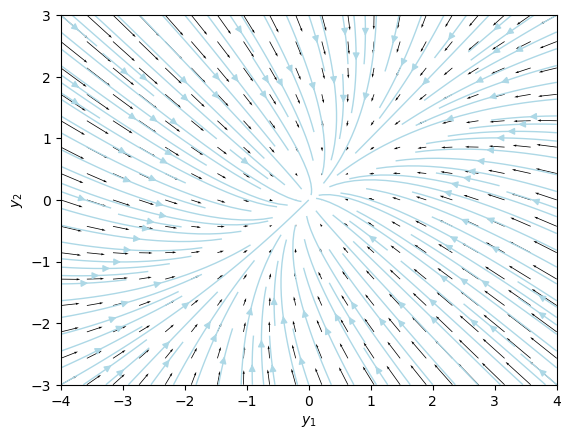

In [6]:
# coordenadas dos pontos a serem plotados
Y1, Y2 = np.meshgrid(np.linspace(-4, 4, 20),
                     np.linspace(-3, 3, 15))

V1 = -3*Y1 + Y2
V2 = Y1 - 3*Y2

plt.quiver(Y1, Y2, V1, V2, width=0.0015, angles='xy')
plt.streamplot(Y1, Y2, V1, V2, color='lightblue', density=1.5, linewidth=1)
plt.xlabel('$y_1$')
plt.ylabel('$y_2$')
plt.show()

As trajetórias no plano de fase dão uma boa impressão qualitativa geral de uma família inteira de soluções. Esse método torna-se particularmente importante nos casos em que a resolução de uma EDO ou de um sistema é inconveniente ou impossível.

Neste exemplo, porém, a solução analítica pode ser obtida facilmente com o `sp.dsolve`, que aceita uma lista de equações:

In [7]:
y1 = sp.Function('y1')
y2 = sp.Function('y2')
eqs = [sp.Eq(y1(t).diff(t), -3*y1(t) + y2(t)),
       sp.Eq(y2(t).diff(t),  y1(t) - 3*y2(t))]
sol = sp.dsolve(eqs, [y1(t), y2(t)])
sol

Ou seja, a solução geral do sistema é

$$
\mathbf{y}=\left[\begin{array}{l}
y_1 \\
y_2
\end{array}\right]=c_1\left[\begin{array}{l}
1 \\
1
\end{array}\right] e^{-2 t}+c_2\left[\begin{array}{r}
1 \\
-1
\end{array}\right] e^{-4 t}
$$

(o SymPy pode apresentar as constantes com outros nomes ou sinais, o que dá a mesma família de soluções). Os números $-2$ e $-4$ e os vetores $(1,1)$ e $(1,-1)$ são os autovalores e autovetores da matriz $\mathbf{A}$ — como calculá-los e como montar a solução geral a partir deles é o assunto dos Notebooks 12 e 13.

Vamos plotar algumas soluções particulares. À esquerda, as componentes $y_1(t)$ e $y_2(t)$ contra $t$; à direita, as mesmas soluções como trajetórias $(y_1(t),y_2(t))$ sobre o retrato de fase.

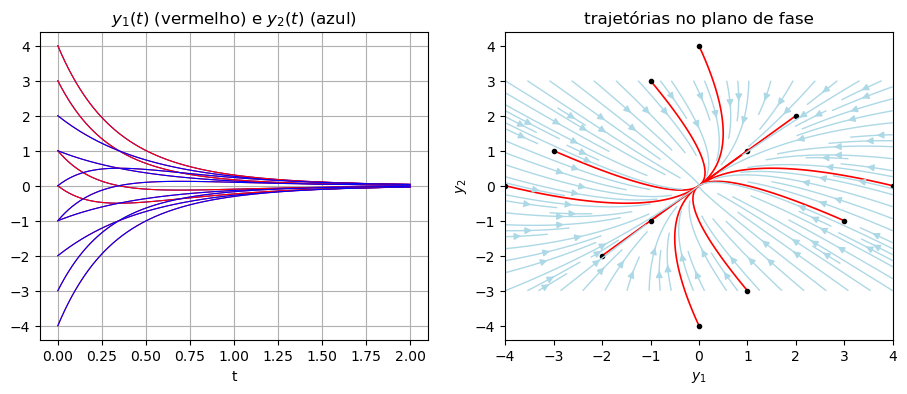

In [8]:
y1_ex = lambda c1, c2, t: c1*np.exp(-2*t) + c2*np.exp(-4*t)
y2_ex = lambda c1, c2, t: c1*np.exp(-2*t) - c2*np.exp(-4*t)

ts = np.linspace(0, 2, 100)
constantes = [(c1, c2) for c1 in (-2, -1, 1, 2) for c2 in (-2, 0, 2)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for c1, c2 in constantes:
    ax1.plot(ts, y1_ex(c1, c2, ts), 'r', lw=0.8)
    ax1.plot(ts, y2_ex(c1, c2, ts), 'b', lw=0.8)
    ax2.plot(y1_ex(c1, c2, ts), y2_ex(c1, c2, ts), 'r', lw=1.2)
    ax2.plot(y1_ex(c1, c2, 0), y2_ex(c1, c2, 0), 'ko', ms=3)   # ponto inicial
ax1.set_xlabel('t'); ax1.set_title('$y_1(t)$ (vermelho) e $y_2(t)$ (azul)'); ax1.grid()
ax2.streamplot(Y1, Y2, V1, V2, color='lightblue', density=1.2, linewidth=1)
ax2.set_xlabel('$y_1$'); ax2.set_ylabel('$y_2$'); ax2.set_title('trajetórias no plano de fase')
plt.show()

À medida que $t$ cresce, todas as soluções tendem a zero (gráfico da esquerda); no plano de fase, isso aparece como trajetórias que partem do ponto inicial e caminham, tangentes às linhas de fluxo, em direção à origem. Como $e^{-4t}$ decai mais rápido que $e^{-2t}$, perto da origem as trajetórias chegam tangentes à reta $y_2=y_1$ (a direção do autovetor $(1,1)$).

O ponto $\mathbf{y} = \mathbf{0}$ é um ponto comum de todas as trajetórias no plano de fase. É chamado de **ponto crítico**. Há cinco tipos de pontos críticos, dependendo da forma geométrica das trajetórias próximas a eles: **nós impróprios**, **nós próprios**, **pontos de sela**, **centros** e **pontos espirais**. O Exemplo 10.5 é um caso de nó impróprio. A classificação dos pontos críticos é o assunto do Notebook 11.

### 10.4 Sistemas autônomos e pontos de equilíbrio

Os sistemas para os quais campos de direções e trajetórias são especialmente úteis são os ditos **autônomos**, em que o lado direito não depende explicitamente de $t$. Para que o sistema dado na forma matricial

$$
\frac{d \mathbf{x}}{d t}=\mathbf{A x}+\mathbf{b}
$$

seja autônomo, todos os elementos da matriz de coeficientes $\mathbf{A}$ e as componentes do vetor $\mathbf{b}$ têm que ser constantes.

Frequentemente é útil encontrar as **soluções de equilíbrio**, ou pontos críticos, de sistemas autônomos: soluções constantes, em que nada varia com o tempo. Fazemos isso igualando $d\mathbf{x}/dt$ a zero. Dessa forma, obtemos o sistema linear algébrico

$$
\mathbf{A x}=-\mathbf{b}.
$$

Se a matriz de coeficientes $\mathbf{A}$ tem inversa, então o sistema tem uma única solução, o único ponto crítico do sistema. No entanto, se $\mathbf{A}$ é singular, então o sistema não tem solução ou tem uma infinidade de soluções.

O comportamento das trajetórias na vizinhança de pontos críticos pode ser determinado por métodos algébricos (autovalores e autovetores, Notebooks 12 a 14); assim, podem-se obter muitas informações sobre as soluções de sistemas autônomos sem ter que resolver o sistema.

**Exemplo 10.6:** (Adaptado de Brannan e Boyce, 2008, [p. 127](https://integrada.minhabiblioteca.com.br/reader/books/978-85-216-2337-3/pageid/148))

Considere os dois tanques interligados, conforme a figura abaixo, contendo em $t=0$ as quantidades de sal $Q_1(0)=55$ e $Q_2(0)=26$ ($t$ em minutos, $Q_1$ e $Q_2$ em onças). A variação de sal em cada tanque é devida, completamente, ao fluxo que entra e sai do tanque, de modo que podemos aplicar o princípio de balanceamento a cada tanque:

*taxa de variação do sal em um tanque = taxa de entrada de sal - taxa de saída de sal*

obtendo assim as equações diferenciais

$$ \frac{dQ_1}{dt}=-0,1 Q_1 + 0,075 Q_2 + 1,5$$

$$ \frac{dQ_2}{dt}=0,1 Q_1 - 0,2 Q_2 + 3$$

O par de equações diferenciais acima, junto com as condições iniciais, constitui um modelo matemático do fluxo entre os dois tanques. Se pudermos resolver estas equações para $Q_1(t)$ e $Q_2(t)$, seremos capazes de prever quanto sal estará em cada tanque em qualquer tempo futuro.

<img src="https://raw.githubusercontent.com/tiagoburiol/MatComp_III/refs/heads/main/Notebook%2010%20-%20Sistemas%20de%20EDOs%2C%20da%20ordem%20superior%20ao%20sistema/imagens/galoes.png" width="480">

*(Um galão americano corresponde a cerca de 3,785 litros; uma onça corresponde a cerca de 28,349 gramas. Abreviaremos galão por gal e onças por oz.)*

Em notação matricial:

$$
\begin{pmatrix}dQ_1/dt\\ dQ_2/dt \end{pmatrix} =
\begin{pmatrix} -0,1 & 0,075 \\ 0,1 & -0,2 \end{pmatrix}
{Q_1 \choose Q_2} +
{1,5 \choose 3}.
$$

Definindo as matrizes

$$\textbf{Q}={Q_1\choose Q_2}, \quad \textbf{K}=\begin{pmatrix} -0,1 & 0,075 \\ 0,1 & -0,2 \end{pmatrix},\quad \textbf{b} = {1,5\choose 3},$$

obtemos o sistema autônomo

$$\frac{d\textbf{Q}}{dt} = \textbf{KQ} + \textbf{b}.$$

As variáveis $Q_1$ e $Q_2$ são chamadas de **variáveis de estado**, já que seu valor em qualquer instante $t$ descreve o estado do sistema, isto é, neste caso, a quantidade de sal em cada tanque. Da mesma forma, o vetor $\textbf{Q}$ é o vetor de estado do sistema e o plano $Q_1Q_2$ é o **plano de estados**, ou plano de fase. À medida que o tempo corre, a ponta do vetor $\textbf{Q}$ descreve uma trajetória no plano de fase, que mostra graficamente a evolução do sistema.

**Ponto de equilíbrio.** Resolvendo $\textbf{KQ}=-\textbf{b}$:

In [9]:
K = np.array([[-0.1, 0.075],
              [ 0.1, -0.2 ]])
b = np.array([1.5, 3])

Q_eq = np.linalg.solve(K, -b)
print(f'Ponto de equilíbrio: Q1 = {Q_eq[0]:.4f},  Q2 = {Q_eq[1]:.4f}')

Ponto de equilíbrio: Q1 = 42.0000,  Q2 = 36.0000


Ou seja, se os tanques tiverem $Q_1=42$ oz e $Q_2=36$ oz de sal, essas quantidades permanecem constantes para sempre: o sal que entra em cada tanque é exatamente compensado pelo que sai.

**Campo de direções.** Em cada ponto $(Q_1,Q_2)$ calculamos o vetor $\textbf{KQ}+\textbf{b}$, que é tangente à trajetória que passa por ali. Como os vetores têm tamanhos muito diferentes, normalizamos as setas (dividimos cada vetor pelo seu comprimento), mostrando só a direção:

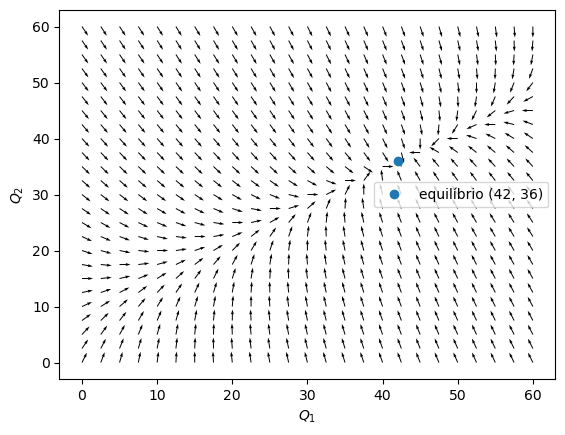

In [10]:
X, Y = np.meshgrid(np.linspace(0, 60, 25),
                   np.linspace(0, 60, 25))
U = -0.1*X + 0.075*Y + 1.5
V =  0.1*X - 0.2*Y + 3

# normalizando as setas (o comprimento é calculado ANTES de alterar U e V)
comprimento = np.sqrt(U**2 + V**2)
U, V = U/comprimento, V/comprimento

plt.quiver(X, Y, U, V, width=0.002)
plt.plot(*Q_eq, 'o', label='equilíbrio (42, 36)')
plt.xlabel('$Q_1$'); plt.ylabel('$Q_2$'); plt.legend()
plt.show()

**Solução particular com `SymPy`.** Usamos `sp.Rational` nos coeficientes para que o SymPy trabalhe com frações exatas — com os decimais `0.1`, `0.075`, ... a resposta viria com números em ponto flutuante difíceis de ler (como vimos no Exemplo 7.6).

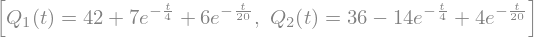

In [11]:
Q1 = sp.Function('Q1')
Q2 = sp.Function('Q2')
R = sp.Rational
eqs = [sp.Eq(Q1(t).diff(t), -R(1,10)*Q1(t) + R(3,40)*Q2(t) + R(3,2)),
       sp.Eq(Q2(t).diff(t),  R(1,10)*Q1(t) - R(1,5)*Q2(t)  + 3)]
sol = sp.dsolve(eqs, [Q1(t), Q2(t)], ics={Q1(0): 55, Q2(0): 26})
sol

A solução tem a forma "equilíbrio + termos que decaem": $Q_1(t)=42+7e^{-t/4}+6e^{-t/20}$ e $Q_2(t)=36-14e^{-t/4}+4e^{-t/20}$. Quando $t\to\infty$, as exponenciais vão a zero e as quantidades de sal tendem ao equilíbrio $(42,36)$.

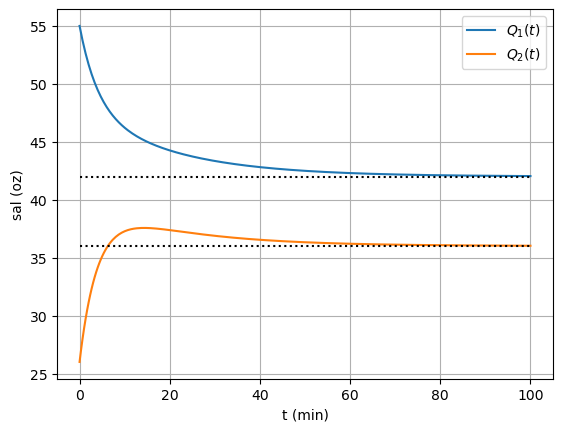

In [12]:
ts = np.linspace(0, 100, 300)
q1 = sp.lambdify(t, sol[0].rhs)
q2 = sp.lambdify(t, sol[1].rhs)

plt.plot(ts, q1(ts), label='$Q_1(t)$')
plt.plot(ts, q2(ts), label='$Q_2(t)$')
plt.hlines(Q_eq, ts[0], ts[-1], colors='black', linestyles=':')
plt.xlabel('t (min)'); plt.ylabel('sal (oz)'); plt.legend(); plt.grid()
plt.show()

**Trajetórias no plano de fase.** Para ver o comportamento a partir de várias condições iniciais diferentes, é mais prático resolver numericamente com `solve_ivp` do que chamar o `sp.dsolve` para cada uma:

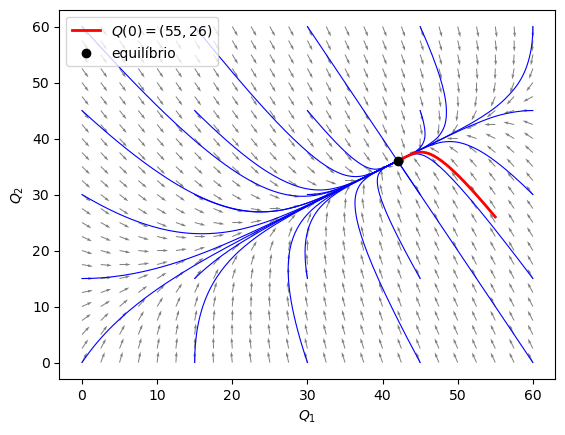

In [13]:
def F_tanques(t, Q):
    return K @ Q + b

for Q10 in np.linspace(0, 60, 5):
    for Q20 in np.linspace(0, 60, 5):
        s = solve_ivp(F_tanques, (0, 100), [Q10, Q20], t_eval=np.linspace(0, 100, 300))
        plt.plot(s.y[0], s.y[1], 'b-', lw=0.8)

plt.plot(q1(ts), q2(ts), 'r-', lw=2, label='$Q(0)=(55,26)$')
plt.quiver(X, Y, U, V, width=0.002, color='gray')
plt.plot(*Q_eq, 'ko', label='equilíbrio')
plt.xlabel('$Q_1$'); plt.ylabel('$Q_2$'); plt.legend()
plt.show()

Todas as trajetórias convergem para o ponto de equilíbrio $(42,36)$, independentemente da condição inicial: o equilíbrio é **assintoticamente estável**. Estabilidade é o assunto do Notebook 14.

#### Atividade 10.3

Suponha que a concentração de sal na água que entra no tanque 2 seja reduzida, de modo que o vetor $\textbf{b}$ do Exemplo 10.6 passe a ser $\textbf{b}=\binom{1,5}{1,5}$ (a matriz $\textbf{K}$ não muda). Encontre o novo ponto de equilíbrio, obtenha com `sp.dsolve` a solução com $Q_1(0)=55$ e $Q_2(0)=26$ e faça o gráfico de $Q_1(t)$ e $Q_2(t)$ para $0\le t\le100$.

### 10.5 Exercícios

**1.** (Adaptado de Boyce e DiPrima, [2020](https://integrada.minhabiblioteca.com.br/reader/books/9788521637134/epubcfi/6/38%5B%3Bvnd.vst.idref%3Dchapter07%5D!/4/550/6/11:14%5Bepr%2Cese%5D)) Para cada um dos sistemas homogêneos dados abaixo, verifique se as funções vetoriais $\mathbf{x}^{(1)}$ e $\mathbf{x}^{(2)}$ são soluções. Em caso afirmativo, verifique que a combinação linear das soluções também é uma solução.

a) $\mathbf{x}^{\prime}=\left(\begin{array}{ll}2 & -1 \\ 3 & -2\end{array}\right) \mathbf{x} ; \quad \mathbf{x}^{(1)}=\binom{1}{1} e^{t}, \quad \mathbf{x}^{(2)}=\binom{1}{3} e^{-t}$

b) $\mathbf{x}^{\prime}=\left(\begin{array}{rr}1 & 1 \\ 4 & -2\end{array}\right) \mathbf{x} ; \quad \mathbf{x}^{(1)}=\binom{1}{-4} e^{-3 t}, \quad \mathbf{x}^{(2)}=\binom{1}{1} e^{2 t}$

c) $\mathbf{x}^{\prime}=\left(\begin{array}{cc}2 & -5 \\ 1 & -2\end{array}\right) \mathbf{x} ; \quad \mathbf{x}^{(1)}=\binom{5 \cos t}{2 \cos t+\operatorname{sen} t}, \quad \mathbf{x}^{(2)}=\binom{5 \operatorname{sen} t}{2 \operatorname{sen} t-\cos t}$

d) $\mathbf{x}^{\prime}=\left(\begin{array}{ll}4 & -2 \\ 8 & -4\end{array}\right) \mathbf{x} ; \quad \mathbf{x}^{(1)}=\binom{2}{4}, \quad \mathbf{x}^{(2)}=\binom{2}{4} t+\binom{0}{-1}$

e) $t \mathbf{x}^{\prime}=\left(\begin{array}{ll}2 & -1 \\ 3 & -2\end{array}\right) \mathbf{x}\ (t>0) ; \quad \mathbf{x}^{(1)}=\binom{1}{1} t, \quad \mathbf{x}^{(2)}=\binom{1}{3} t^{-1}$

f) $t \mathbf{x}^{\prime}=\left(\begin{array}{ll}3 & -2 \\ 2 & -2\end{array}\right) \mathbf{x}\ (t>0) ; \quad \mathbf{x}^{(1)}=\binom{1}{2} t^{-1}, \quad \mathbf{x}^{(2)}=\binom{2}{1} t^2$

**2.** Escreva cada problema abaixo como um sistema de EDOs de 1ª ordem (na forma matricial, quando for linear) e resolva-o numericamente com `solve_ivp`.

a) $y^{(4)}-y=0$, com $y(0)=1$, $y'(0)=0$, $y''(0)=-1$, $y^{\prime\prime\prime}(0)=0$, no intervalo $[0,10]$. Verifique que $y(t)=\cos t$ é a solução exata e calcule o erro máximo da solução numérica.

b) O sistema acoplado $x''=-2x+y$, $y''=x-2y+\cos t$, com $x(0)=y(0)=0$ e $x'(0)=y'(0)=0$, no intervalo $[0,20]$. Faça os gráficos de $x(t)$ e $y(t)$.

**3.** O pêndulo não linear $\theta''=-\frac{g}{l}\,sen\,\theta$ (Exercício 1 do Notebook 8), com $g=9,8$ e $l=1$, pode ser escrito como o sistema autônomo $\theta'=\omega$, $\omega'=-9,8\,sen\,\theta$.

a) Encontre os pontos de equilíbrio do sistema no intervalo $-2\pi\le\theta\le2\pi$ e interprete-os fisicamente.

b) Desenhe o retrato de fase (`streamplot`) no retângulo $-2\pi\le\theta\le2\pi$, $-8\le\omega\le8$.

c) Sobreponha as trajetórias obtidas com `solve_ivp` a partir de $\theta(0)=0$ e $\omega(0)=2$, $\omega(0)=4$, $\omega(0)=6$ e $\omega(0)=7$, no intervalo $[0,5]$. Qual é a diferença qualitativa entre as trajetórias com $\omega(0)=6$ e $\omega(0)=7$? O que ela significa para o movimento do pêndulo?

**Referências**

BOYCE, William E.; DIPRIMA, Richard C. Equações Diferenciais Elementares e Problemas de Valores de Contorno. Grupo GEN, 2020. E-book. ISBN 9788521637134. Disponível em: https://integrada.minhabiblioteca.com.br/#/books/9788521637134/.

BRANNAN, James R.; BOYCE, William E. Equações Diferenciais: uma Introdução a Métodos Modernos e suas Aplicações. São Paulo: Grupo GEN, 2008. E-book. ISBN 978-85-216-2337-3. Disponível em: https://integrada.minhabiblioteca.com.br/#/books/978-85-216-2337-3/.

KREYSZIG, Erwin. Matemática Superior para Engenharia. 9. ed. Rio de Janeiro: LTC, 2008. v. 2.